# 04 – Mô phỏng Monte Carlo

**Mục tiêu** (mục 3 của đề bài và mở rộng)
1. Sinh số ngẫu nhiên **tái lập được** với `np.random.default_rng(seed)`.
2. Viết lại hàm `poissonsim(mu, n, mode)` như script của đề bài (xuất CSV + vẽ).
3. Mô phỏng 1000 lần thử cho các µ đo được và so sánh với thực nghiệm.
4. Khảo sát sự **hội tụ** của trung bình và độ lệch chuẩn theo số lần thử.
5. Mô phỏng **vật lý** của ống đếm: thời điểm xung là quá trình Poisson (khoảng cách thời gian phân bố mũ) → kiểm chứng phân bố số đếm; ảnh hưởng của **thời gian chết**.
6. Minh họa giới hạn nhị thức → Poisson.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from du_lieu import doc_so_lieu, TEN_BO, T_NGAN, T_DAI   # module đọc số liệu (xem notebook 01)

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
data, N100 = doc_so_lieu()
data.head()

,S1,S2,S3
lan_do,,,
1,10,40,126
2,9,26,115
3,7,33,109
4,9,34,128
5,5,37,134


## 1. Bộ sinh số ngẫu nhiên và `seed`

- Dùng API mới `rng = np.random.default_rng(seed)` (thay cho `np.random.seed` cũ).
- Cùng `seed` → cùng dãy số → **kết quả tái lập được** (bắt buộc khi đưa vào báo cáo).

In [2]:
rng = np.random.default_rng(2026)
print(rng.poisson(5.52, size=10))
print(np.random.default_rng(2026).poisson(5.52, size=10), "← cùng seed, cùng kết quả")

[ 7 10  4  5  9  6  6  4  7  9]
[ 7 10  4  5  9  6  6  4  7  9] ← cùng seed, cùng kết quả


## 2. Viết lại hàm `poissonsim(mu, n, mode)`

Theo mô tả trong đề: tạo mẫu `n` lần thử với trung bình `mu`, lưu CSV hai cột (số đếm, tần suất),
vẽ Poisson lý thuyết (đường) + mẫu (điểm đỏ); `mode='gaus'` vẽ thêm Gauss.

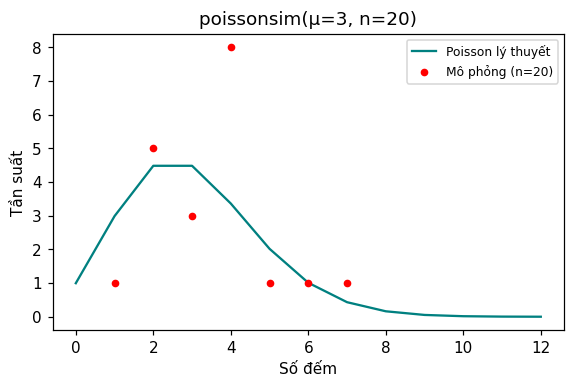

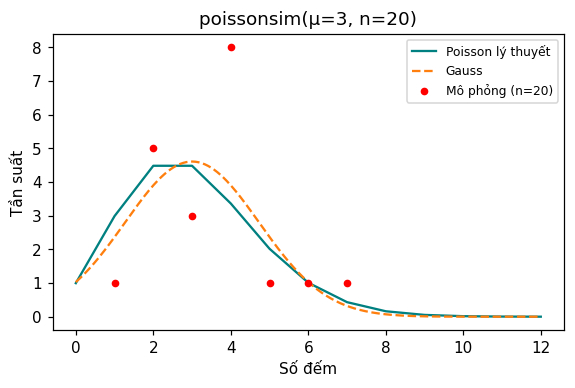

In [3]:
from pathlib import Path

def poissonsim(mu, n, mode="", seed=None, luu_csv=True, ax=None):
    rng = np.random.default_rng(seed)
    mau = rng.poisson(mu, n)
    k = np.arange(mau.min(), mau.max() + 1)
    O = np.bincount(mau)[k]
    if luu_csv:
        Path("mo_phong").mkdir(exist_ok=True)
        pd.DataFrame({"so_dem": k, "tan_suat": O}).to_csv(f"mo_phong/poissonsim_mu{mu}_n{n}.csv", index=False)
    ax = ax or plt.subplots(figsize=(6, 3.5))[1]
    kk = np.arange(max(0, int(mu - 5 * np.sqrt(mu))), int(mu + 5 * np.sqrt(mu)) + 2)
    ax.plot(kk, n * stats.poisson.pmf(kk, mu), "-", color="teal", label="Poisson lý thuyết")
    if mode == "gaus":
        xs = np.linspace(kk.min(), kk.max(), 300)
        ax.plot(xs, n * stats.norm.pdf(xs, mu, np.sqrt(mu)), "--", color="C1", label="Gauss")
    ax.plot(k, O, "o", color="red", ms=4, label=f"Mô phỏng (n={n})")
    ax.set(title=f"poissonsim(µ={mu}, n={n})", xlabel="Số đếm", ylabel="Tần suất"); ax.legend(fontsize=8)
    return mau

_ = poissonsim(3, 20, seed=1)                 # ví dụ trong đề: poissonsim(3, 20, '')
_ = poissonsim(3, 20, "gaus", seed=1)         # poissonsim(3, 20, 'gaus')

## 3. 1000 lần thử với µ đo được – so sánh với thực nghiệm

So sánh **mật độ** (chuẩn hóa `density=True`) vì hai mẫu có cỡ khác nhau (1000 và 100).

,Bộ,µ,x̄ MC,u(x̄ MC),s thực nghiệm,s MC,√µ
0,S1,5.52,5.669,0.076,2.464,2.394,2.349
1,S2,41.22,41.094,0.205,7.038,6.476,6.420
2,S3,112.19,111.928,0.330,11.348,10.438,10.592


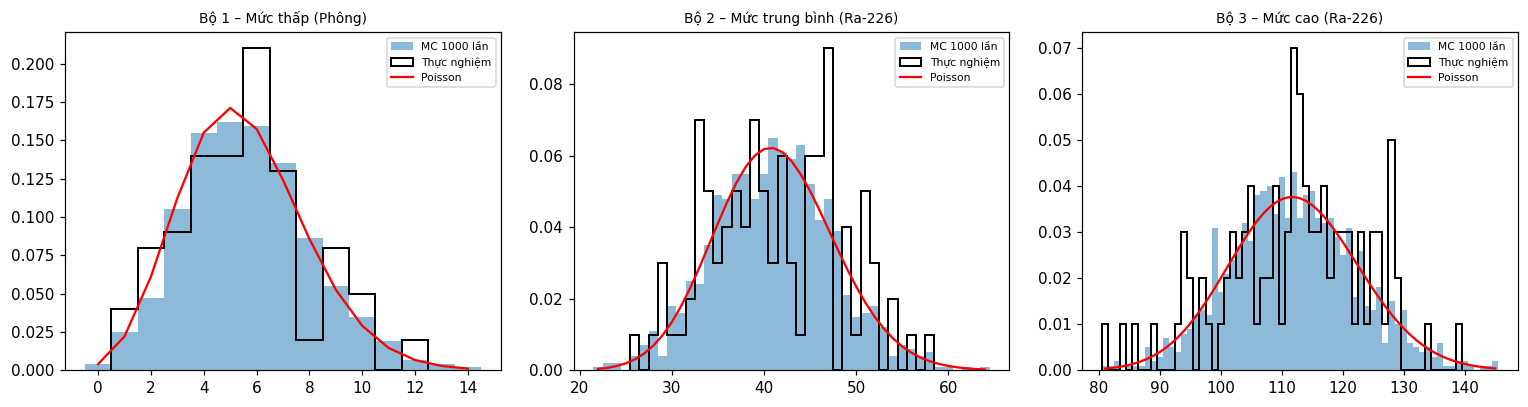

In [4]:
N_MC = 1000
rng = np.random.default_rng(2026)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
rows = []
for ax, bo in zip(axes, data):
    x = data[bo].to_numpy(); mu = x.mean()
    mc = rng.poisson(mu, N_MC)
    ax.hist(mc, bins=np.arange(mc.min() - .5, mc.max() + 1.5), density=True, alpha=.5, label=f"MC {N_MC} lần")
    ax.hist(x, bins=np.arange(x.min() - .5, x.max() + 1.5), density=True, histtype="step", color="k", lw=1.3, label="Thực nghiệm")
    kk = np.arange(mc.min(), mc.max() + 1)
    ax.plot(kk, stats.poisson.pmf(kk, mu), "r-", label="Poisson")
    ax.set_title(TEN_BO[bo], fontsize=9); ax.legend(fontsize=7)
    rows.append([bo, mu, mc.mean(), mc.std(ddof=1) / np.sqrt(N_MC), x.std(ddof=1), mc.std(ddof=1), np.sqrt(mu)])
fig.tight_layout()
pd.DataFrame(rows, columns=["Bộ", "µ", "x̄ MC", "u(x̄ MC)", "s thực nghiệm", "s MC", "√µ"]).round(3)

## 4. Hội tụ theo số lần thử – luật số lớn

Trung bình mẫu hội tụ về µ với sai số $\sigma/\sqrt N$; độ lệch chuẩn mẫu hội tụ về $\sqrt\mu$.

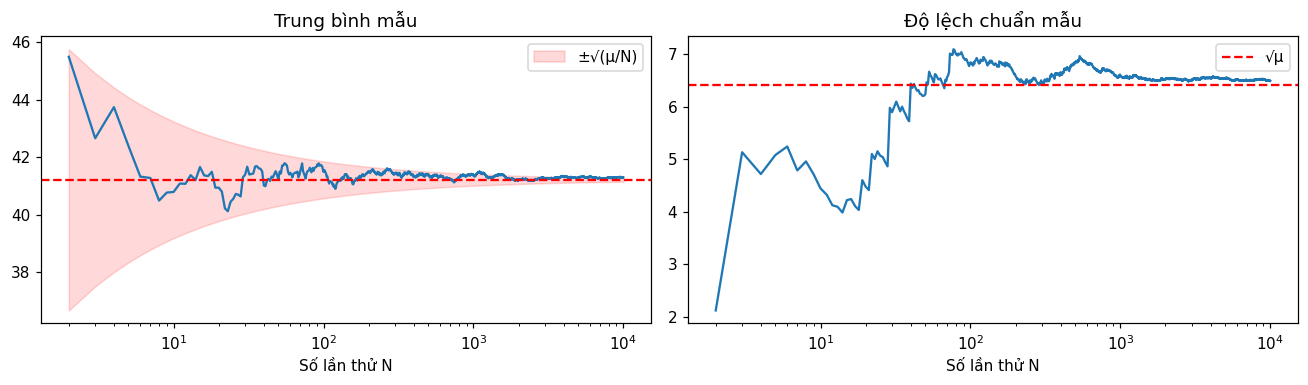

In [5]:
mu = data.S2.mean()
mau = np.random.default_rng(7).poisson(mu, 10_000)
N = np.arange(2, len(mau) + 1)
tb = np.cumsum(mau)[1:] / N
# độ lệch chuẩn tích lũy (ddof=1) bằng công thức tổng bình phương
s = np.sqrt((np.cumsum(mau ** 2)[1:] - N * tb ** 2) / (N - 1))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].semilogx(N, tb); axes[0].axhline(mu, color="r", ls="--")
axes[0].fill_between(N, mu - np.sqrt(mu / N), mu + np.sqrt(mu / N), color="r", alpha=.15, label="±√(µ/N)")
axes[0].set(title="Trung bình mẫu", xlabel="Số lần thử N"); axes[0].legend()
axes[1].semilogx(N, s); axes[1].axhline(np.sqrt(mu), color="r", ls="--", label="√µ")
axes[1].set(title="Độ lệch chuẩn mẫu", xlabel="Số lần thử N"); axes[1].legend()
fig.tight_layout()

## 5. Thí nghiệm của nhóm có “bình thường” không? – lặp lại hàng nghìn thí nghiệm ảo

💡 **Kỹ thuật:** sinh mảng 2 chiều `(số thí nghiệm, 100)` rồi tính theo `axis=1` – nhanh hơn vòng `for` hàng trăm lần.

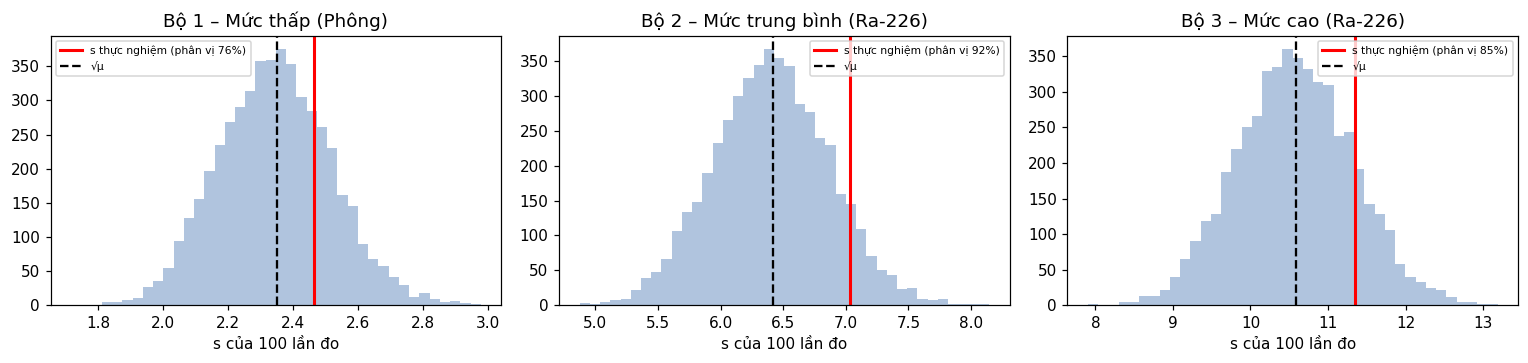

In [6]:
N_REP = 5000
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
for ax, bo in zip(axes, data):
    x = data[bo].to_numpy(); mu = x.mean()
    ao = np.random.default_rng(11).poisson(mu, size=(N_REP, len(x)))
    s_ao = ao.std(axis=1, ddof=1)
    phan_vi = (s_ao < x.std(ddof=1)).mean() * 100
    ax.hist(s_ao, bins=40, color="lightsteelblue")
    ax.axvline(x.std(ddof=1), color="r", lw=2, label=f"s thực nghiệm (phân vị {phan_vi:.0f}%)")
    ax.axvline(np.sqrt(mu), color="k", ls="--", label="√µ")
    ax.set(title=TEN_BO[bo], xlabel="s của 100 lần đo"); ax.legend(fontsize=7)
fig.tight_layout()

Độ lệch chuẩn thực nghiệm nằm trong vùng phân bố của các thí nghiệm ảo → khác biệt $s$ so với $\sqrt\mu$ chỉ là **thăng giáng thống kê** của mẫu 100 lần đo.

## 6. Mô phỏng vật lý: chuỗi xung của ống đếm Geiger–Müller

Phân rã phóng xạ là **quá trình Poisson**: khoảng thời gian giữa hai xung liên tiếp tuân theo **phân bố mũ**
$f(\Delta t)=R\,e^{-R\Delta t}$. Mô phỏng thời điểm xung, rồi đếm trong các cửa sổ 10 s → phải thu được phân bố Poisson.

Số xung: 11338, trung bình/10 s = 113.38, s = 10.47, √µ = 10.65


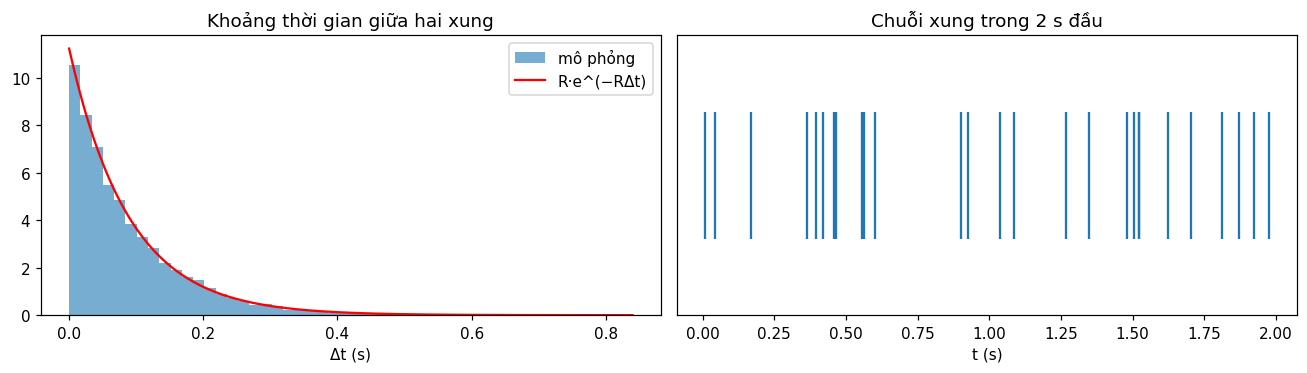

In [7]:
R = data.S3.mean() / T_NGAN                      # tốc độ đếm Bộ 3 (s⁻¹)
rng = np.random.default_rng(3)
T_tong = 100 * T_NGAN                              # 100 cửa sổ × 10 s
dt = rng.exponential(1 / R, size=int(R * T_tong * 1.5))   # khoảng cách giữa các xung
thoi_diem = np.cumsum(dt)
thoi_diem = thoi_diem[thoi_diem < T_tong]

dem = np.histogram(thoi_diem, bins=np.arange(0, T_tong + T_NGAN, T_NGAN))[0]   # số đếm mỗi cửa sổ 10 s
print(f"Số xung: {len(thoi_diem)}, trung bình/10 s = {dem.mean():.2f}, s = {dem.std(ddof=1):.2f}, √µ = {np.sqrt(dem.mean()):.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(np.diff(thoi_diem), bins=50, density=True, alpha=.6, label="mô phỏng")
tt = np.linspace(0, np.diff(thoi_diem).max(), 200)
axes[0].plot(tt, R * np.exp(-R * tt), "r-", label="R·e^(−RΔt)")
axes[0].set(title="Khoảng thời gian giữa hai xung", xlabel="Δt (s)"); axes[0].legend()
axes[1].eventplot(thoi_diem[thoi_diem < 2], lineoffsets=0, linelengths=0.8)
axes[1].set(title="Chuỗi xung trong 2 s đầu", xlabel="t (s)", yticks=[])
fig.tight_layout()

### Ảnh hưởng của thời gian chết τ

Sau mỗi xung, ống GM “mù” trong thời gian τ (cỡ 100 µs). Xung đến trong khoảng đó bị **mất** →
tốc độ đếm giảm và phương sai **nhỏ hơn** trung bình ($D<1$). Phóng đại τ để thấy rõ hiệu ứng:

In [8]:
def ap_thoi_gian_chet(t, tau):
    """Loại các xung đến trong thời gian chết (kiểu không kéo dài – non-paralyzable)."""
    giu, cuoi = [], -np.inf
    for ti in t:
        if ti - cuoi >= tau:
            giu.append(ti); cuoi = ti
    return np.array(giu)

R_cao = 200.0                                    # tốc độ đếm cao (s⁻¹) để hiệu ứng rõ
t = np.cumsum(np.random.default_rng(5).exponential(1 / R_cao, int(R_cao * 1000 * 1.2)))
t = t[t < 1000]
rows = []
for tau in [0, 1e-4, 1e-3, 2e-3]:
    tg = ap_thoi_gian_chet(t, tau) if tau else t
    dem = np.histogram(tg, bins=np.arange(0, 1001, 1))[0]       # cửa sổ 1 s
    rows.append([tau * 1e6, dem.mean(), dem.var(ddof=1) / dem.mean(), R_cao / (1 + R_cao * tau)])
pd.DataFrame(rows, columns=["τ (µs)", "trung bình/1 s", "D = s²/x̄", "lý thuyết R/(1+Rτ)"]).round(3)

,τ (µs),trung bình/1 s,D = s²/x̄,lý thuyết R/(1+Rτ)
0,0.0,200.296,1.012,200.000
1,100.0,196.443,0.978,196.078
2,1000.0,166.850,0.690,166.667
3,2000.0,142.876,0.516,142.857


Ở tốc độ đếm của nhóm (≤ 12 s⁻¹) và τ ~ 100 µs, $R\tau \approx 0{,}1\%$ → hiệu ứng không đáng kể, phù hợp với $D\approx 1$ đo được.

## 7. Giới hạn nhị thức → Poisson

$n$ phép thử, xác suất $p$, giữ $np=\mu$ cố định: khi $n\to\infty$, phân bố nhị thức → Poisson.

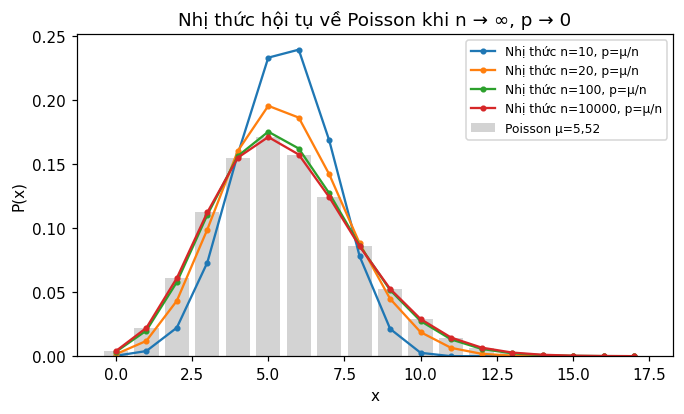

In [9]:
mu = 5.52
k = np.arange(0, 18)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(k, stats.poisson.pmf(k, mu), color="lightgray", label="Poisson µ=5,52")
for n_thu in [10, 20, 100, 10_000]:
    ax.plot(k, stats.binom.pmf(k, n_thu, mu / n_thu), "o-", ms=3, label=f"Nhị thức n={n_thu}, p=µ/n")
ax.set(xlabel="x", ylabel="P(x)", title="Nhị thức hội tụ về Poisson khi n → ∞, p → 0"); ax.legend(fontsize=8)

## 📝 Bài tập
1. Dùng `poissonsim` với µ = 8, 50, 100 và n = 1000 (đúng yêu cầu đề bài), so sánh trung bình và độ lệch chuẩn với số liệu thực nghiệm.
2. Trong mục 6, thay phân bố mũ bằng **phân bố đều** cho Δt (cùng trung bình 1/R). Phân bố số đếm còn là Poisson không? D bằng bao nhiêu? Giải thích.
3. Ước lượng thời gian chết τ cần thiết để D giảm xuống 0,9 ở tốc độ đếm 200 s⁻¹. *(Gợi ý: với thời gian chết không kéo dài, $D\approx(1+R\tau)^{-2}$.)*
4. Mô phỏng “nguồn trôi”: cho µ tăng tuyến tính 5% trong 100 lần đo. Vẽ $r_c(j)$ và tính $D$ – có phát hiện được không?